<a href="https://colab.research.google.com/github/KateT840/Espectrografia-astronomica/blob/main/Granulaci%C3%B3n_solar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

archivo = files.upload()

Saving iag 5000 5030.xlsx to iag 5000 5030.xlsx


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

nombre = list(archivo.keys())[0]

# Leer el Excel sin encabezados
datos = pd.read_excel(nombre, header=None)

# Conservar únicamente las filas que contienen datos
datos = datos.iloc[4:].copy()

# Asignar nombres a las columnas
datos.columns = ['k', 'lambda_vacio', 'flujo']

# Convertir las columnas a números
for columna in ['k', 'lambda_vacio', 'flujo']:
    datos[columna] = pd.to_numeric(datos[columna], errors='coerce')

# Eliminar filas que no sean numéricas
datos = datos.dropna().reset_index(drop=True)

# Revisar
datos.head()

,k,lambda_vacio,flujo
0,19999.996936,5000.000766,0.994788
1,19999.993169,5000.001708,0.995077
2,19999.989402,5000.002649,0.995980
3,19999.985636,5000.003591,0.996553
4,19999.981869,5000.004533,0.995997


In [4]:
print(datos.dtypes)
print(datos.shape)
print(datos.head())

k               float64
lambda_vacio    float64
flujo           float64
dtype: object
(31669, 3)
              k  lambda_vacio     flujo
0  19999.996936   5000.000766  0.994788
1  19999.993169   5000.001708  0.995077
2  19999.989402   5000.002649  0.995980
3  19999.985636   5000.003591  0.996553
4  19999.981869   5000.004533  0.995997


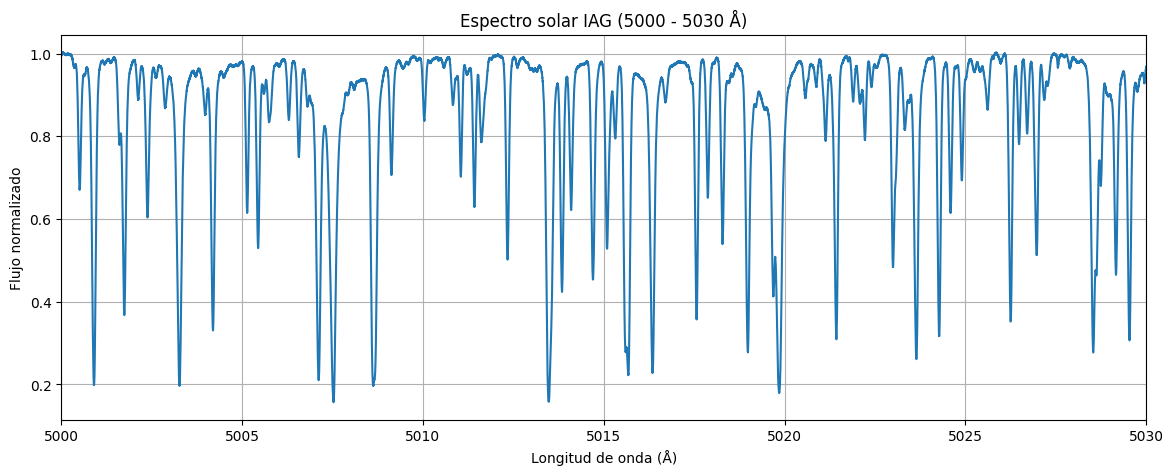

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(datos['lambda_vacio'], datos['flujo'])

plt.xlabel('Longitud de onda (Å)')
plt.ylabel('Flujo normalizado')
plt.title('Espectro solar IAG (5000 - 5030 Å)')

plt.xlim(5000, 5030)
plt.grid()

plt.savefig('espectro_solar_IAG.png', dpi=300, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('espectro_solar_IAG.png')

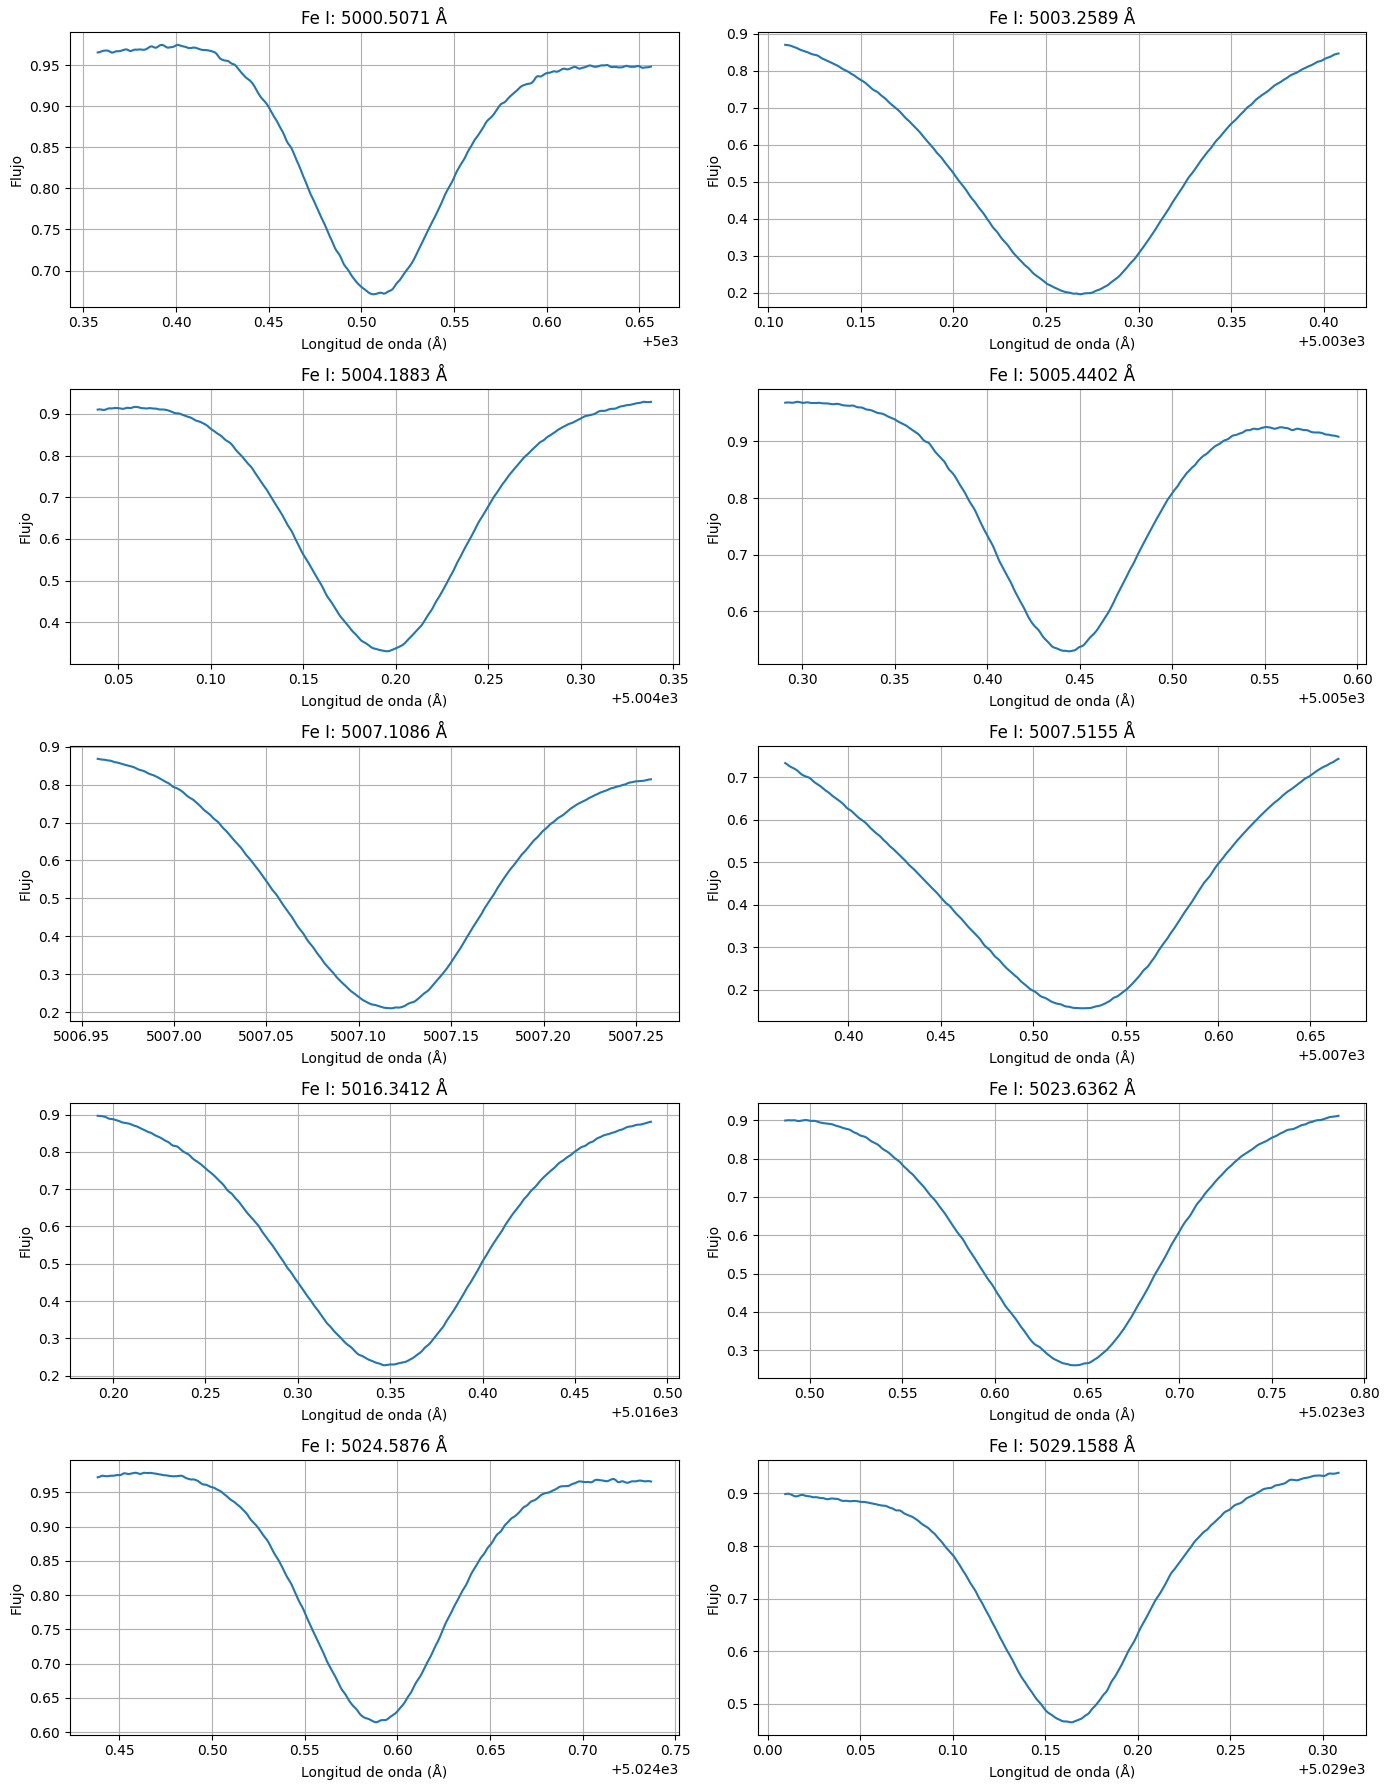

In [14]:
# Longitudes de onda de referencia del profesor
lineas = [
    5000.5071,
    5003.2589,
    5004.1883,
    5005.4402,
    5007.1086,
    5007.5155,
    5016.3412,
    5023.6362,
    5024.5876,
    5029.1588
]

# Crear las gráficas
fig, ejes = plt.subplots(5, 2, figsize=(14, 18))

for i, ax in enumerate(ejes.flat):

    centro = lineas[i]

    # Seleccionar una región de 0.3 Å alrededor de la línea
    region = datos[
        (datos['lambda_vacio'] >= centro - 0.15) &
        (datos['lambda_vacio'] <= centro + 0.15)
    ]

    ax.plot(region['lambda_vacio'], region['flujo'])

    ax.set_title(f'Fe I: {centro} Å')
    ax.set_xlabel('Longitud de onda (Å)')
    ax.set_ylabel('Flujo')
    ax.grid()

plt.tight_layout()
plt.show()

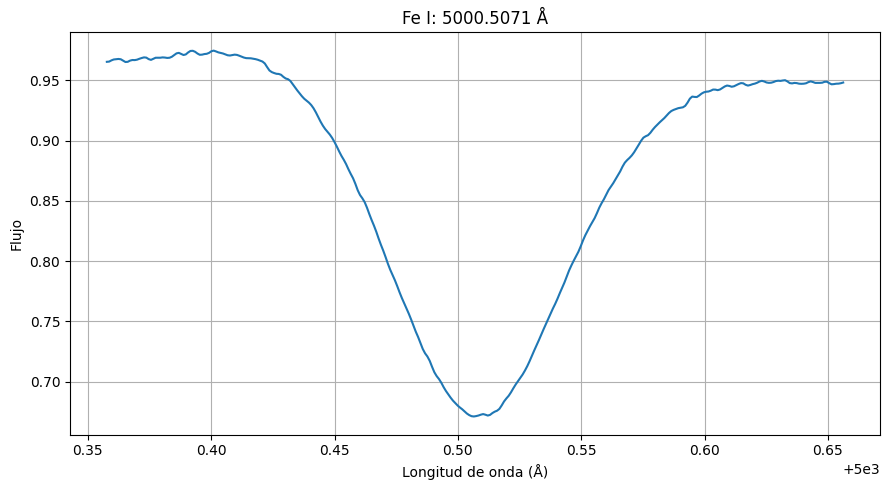

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

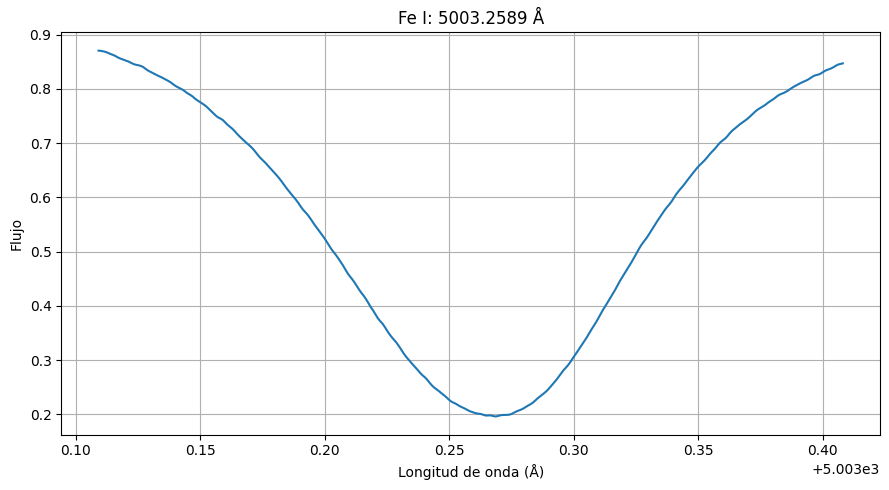

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

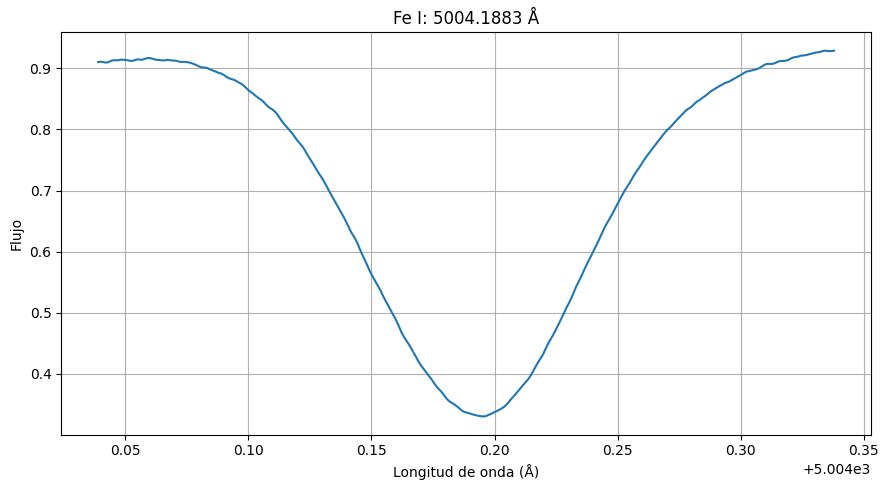

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

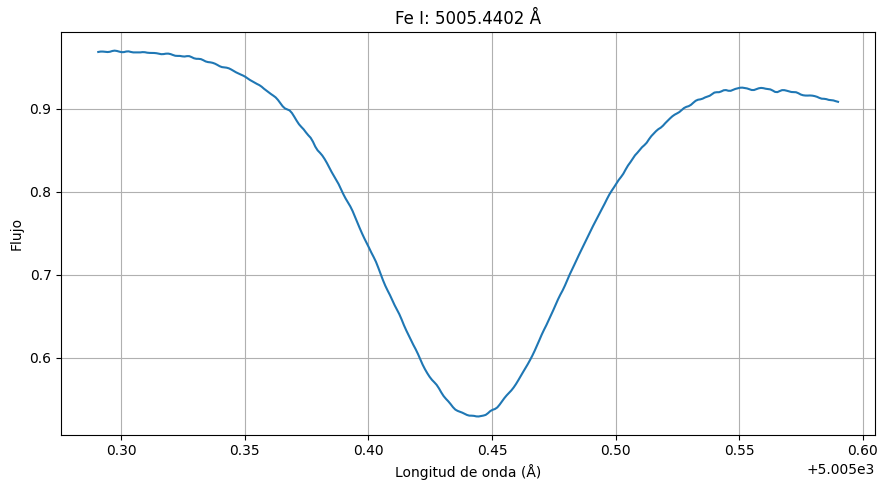

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

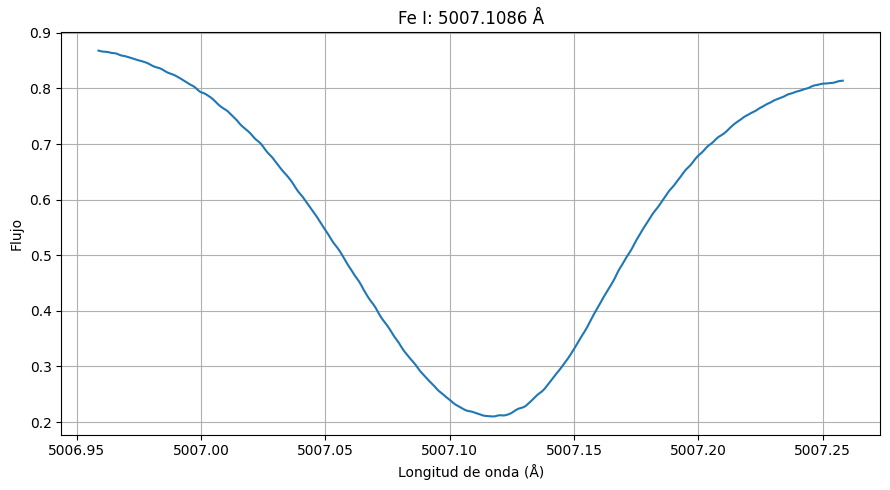

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

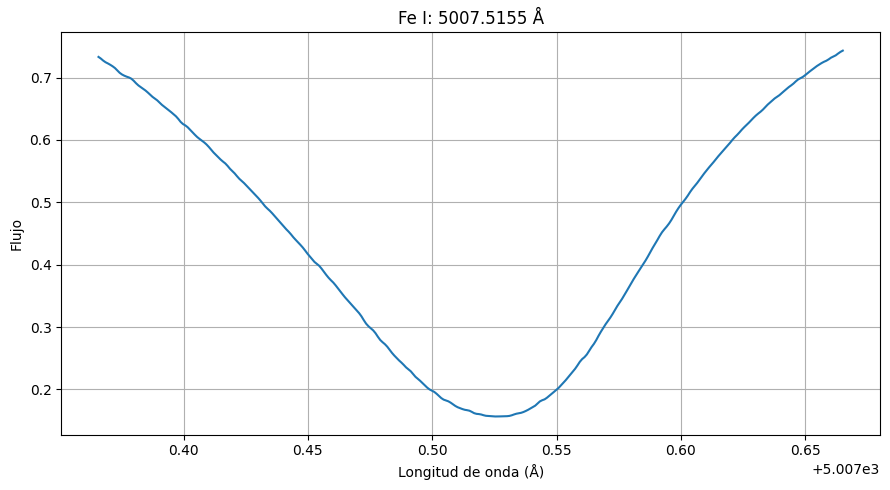

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

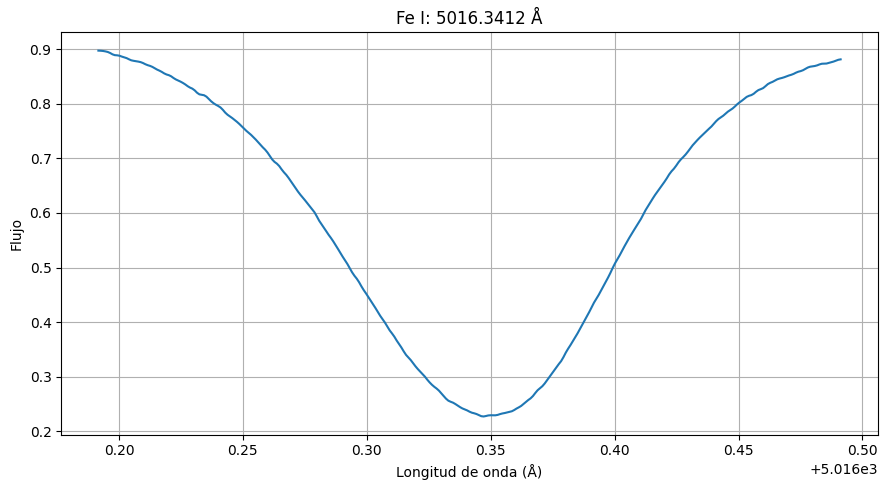

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

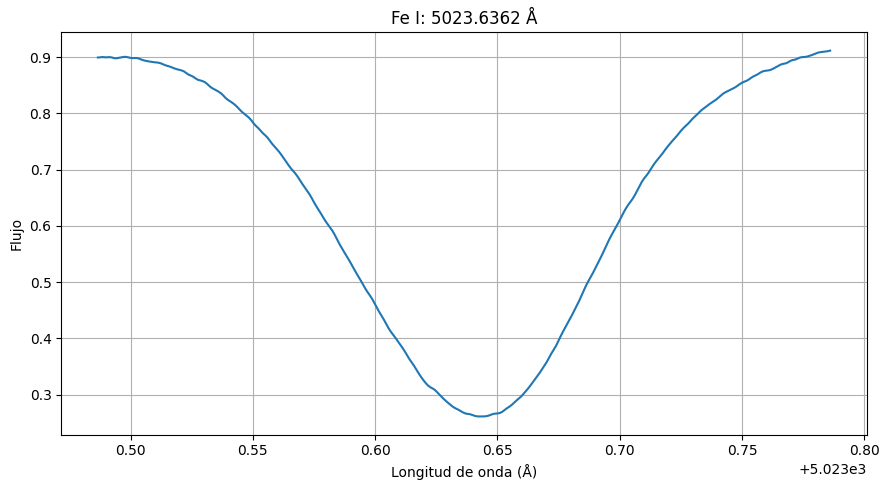

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

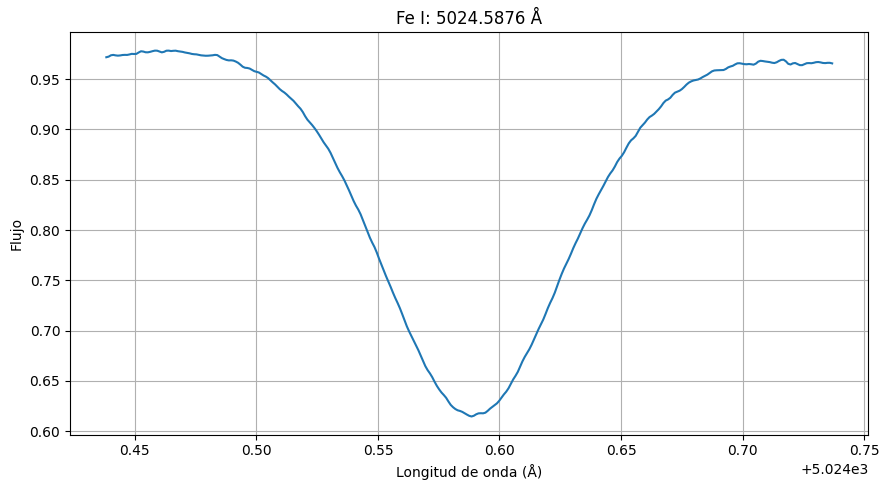

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

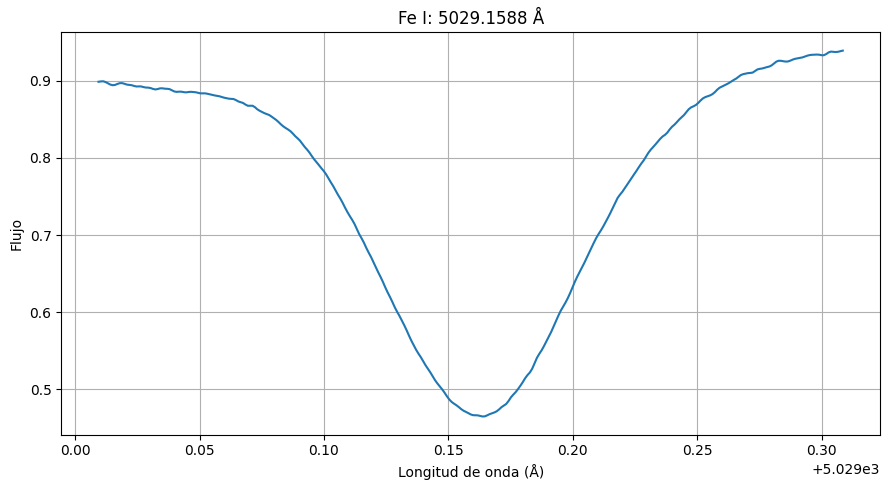

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import files
import matplotlib.pyplot as plt

lineas = [
    5000.5071,
    5003.2589,
    5004.1883,
    5005.4402,
    5007.1086,
    5007.5155,
    5016.3412,
    5023.6362,
    5024.5876,
    5029.1588
]

for i, centro in enumerate(lineas):

    # Seleccionar la región alrededor de la línea
    region = datos[
        (datos['lambda_vacio'] >= centro - 0.15) &
        (datos['lambda_vacio'] <= centro + 0.15)
    ]

    # Crear una figura independiente
    plt.figure(figsize=(9, 5))

    plt.plot(region['lambda_vacio'], region['flujo'])

    plt.title(f'Fe I: {centro} Å')
    plt.xlabel('Longitud de onda (Å)')
    plt.ylabel('Flujo')
    plt.grid()

    plt.tight_layout()

    # Nombre individual para cada imagen
    nombre = f'linea_FeI_{i+1}.png'

    # Guardar y mostrar
    plt.savefig(nombre, dpi=300, bbox_inches='tight')
    plt.show()

    # Descargar individualmente
    files.download(nombre)

    plt.close()

In [17]:
for centro in lineas:

    region = datos[
        (datos['lambda_vacio'] >= centro - 0.15) &
        (datos['lambda_vacio'] <= centro + 0.15)
    ]

    minimo = region.loc[region['flujo'].idxmin()]

    print(f"Línea de referencia: {centro} Å")
    print(f"Centro aproximado: {minimo['lambda_vacio']:.6f} Å")
    print(f"Flujo mínimo: {minimo['flujo']:.6f}")
    print("-----------------------------")

Línea de referencia: 5000.5071 Å
Centro aproximado: 5000.506475 Å
Flujo mínimo: 0.671047
-----------------------------
Línea de referencia: 5003.2589 Å
Centro aproximado: 5003.268487 Å
Flujo mínimo: 0.196306
-----------------------------
Línea de referencia: 5004.1883 Å
Centro aproximado: 5004.195495 Å
Flujo mínimo: 0.330412
-----------------------------
Línea de referencia: 5005.4402 Å
Centro aproximado: 5005.444623 Å
Flujo mínimo: 0.529549
-----------------------------
Línea de referencia: 5007.1086 Å
Centro aproximado: 5007.117392 Å
Flujo mínimo: 0.210009
-----------------------------
Línea de referencia: 5007.5155 Å
Centro aproximado: 5007.525370 Å
Flujo mínimo: 0.156701
-----------------------------
Línea de referencia: 5016.3412 Å
Centro aproximado: 5016.347124 Å
Flujo mínimo: 0.227445
-----------------------------
Línea de referencia: 5023.6362 Å
Centro aproximado: 5023.643467 Å
Flujo mínimo: 0.261014
-----------------------------
Línea de referencia: 5024.5876 Å
Centro aproxima

In [18]:
import numpy as np

resultados = []

for referencia in lineas:

    # Buscar el mínimo aproximado
    region = datos[
        (datos['lambda_vacio'] >= referencia - 0.15) &
        (datos['lambda_vacio'] <= referencia + 0.15)
    ]

    minimo = region.loc[region['flujo'].idxmin()]

    lambda_min = minimo['lambda_vacio']

    # Seleccionar puntos cercanos al mínimo
    nucleo = datos[
        (datos['lambda_vacio'] >= lambda_min - 0.015) &
        (datos['lambda_vacio'] <= lambda_min + 0.015)
    ]

    x = nucleo['lambda_vacio'].to_numpy()
    y = nucleo['flujo'].to_numpy()

    # Centrar las coordenadas para mejorar el ajuste numérico
    x0 = lambda_min

    a, b, c = np.polyfit(x - x0, y, 2)

    # Calcular el vértice de la parábola
    lambda_c = x0 - b / (2*a)

    # Calcular el flujo en el centro
    flujo_c = a*(lambda_c - x0)**2 + b*(lambda_c - x0) + c

    resultados.append([
        referencia,
        lambda_c,
        flujo_c,
        a
    ])

# Crear una tabla con los resultados
tabla = pd.DataFrame(
    resultados,
    columns=['lambda_referencia', 'lambda_centro', 'flujo_centro', 'a']
)

tabla

,lambda_referencia,lambda_centro,flujo_centro,a
0,5000.5071,5000.508682,0.670982,117.102383
1,5003.2589,5003.267923,0.197168,99.215809
2,5004.1883,5004.194077,0.331293,167.000252
3,5005.4402,5005.443212,0.529590,149.025524
4,5007.1086,5007.116972,0.210659,102.541421
5,5007.5155,5007.526012,0.156709,65.685694
6,5016.3412,5016.349464,0.228997,107.081598
7,5023.6362,5023.643382,0.261184,131.142743
8,5024.5876,5024.589244,0.615639,130.883464
9,5029.1588,5029.162676,0.465561,148.586283


In [19]:
# Velocidad de la luz en km/s
c = 299792.458

# Calcular la velocidad Doppler
tabla['velocidad'] = c * (
    (tabla['lambda_centro'] - tabla['lambda_referencia'])
    / tabla['lambda_referencia']
)

tabla

,lambda_referencia,lambda_centro,flujo_centro,a,velocidad
0,5000.5071,5000.508682,0.670982,117.102383,0.094824
1,5003.2589,5003.267923,0.197168,99.215809,0.540633
2,5004.1883,5004.194077,0.331293,167.000252,0.346069
3,5005.4402,5005.443212,0.529590,149.025524,0.180406
4,5007.1086,5007.116972,0.210659,102.541421,0.501273
5,5007.5155,5007.526012,0.156709,65.685694,0.629346
6,5016.3412,5016.349464,0.228997,107.081598,0.493877
7,5023.6362,5023.643382,0.261184,131.142743,0.428592
8,5024.5876,5024.589244,0.615639,130.883464,0.098060
9,5029.1588,5029.162676,0.465561,148.586283,0.231051


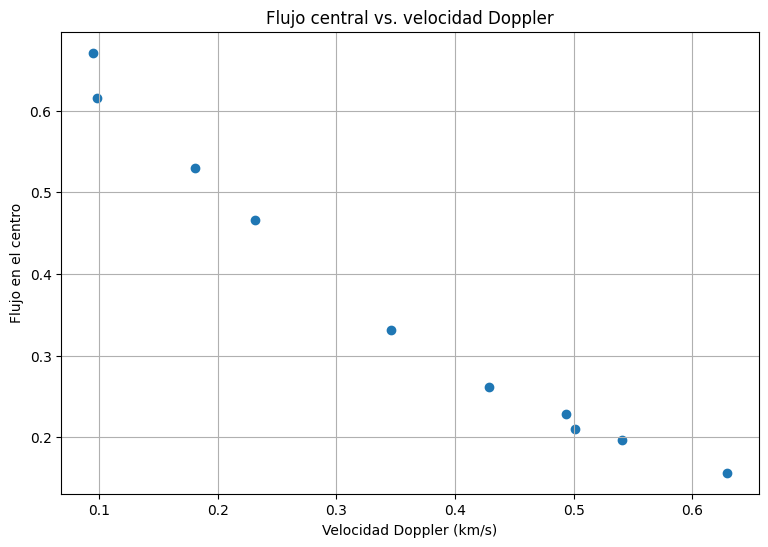

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
plt.figure(figsize=(9, 6))

plt.scatter(
    tabla['velocidad'],
    tabla['flujo_centro']
)

plt.xlabel('Velocidad Doppler (km/s)')
plt.ylabel('Flujo en el centro')
plt.title('Flujo central vs. velocidad Doppler')

plt.grid()
plt.savefig('flujo_central_vs_velocidad_Doppler.png', dpi=300, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('flujo_central_vs_velocidad_Doppler.png')

In [21]:
# Velocidad de la luz en km/s
c = 299792.458

# Corrimiento gravitacional del Sol en km/s
v_gravedad = 0.635

# Calcular la velocidad Doppler
tabla['velocidad'] = c * (
    (tabla['lambda_centro'] - tabla['lambda_referencia'])
    / tabla['lambda_referencia']
)

# Corregir el corrimiento gravitacional
tabla['velocidad_corregida'] = tabla['velocidad'] - v_gravedad

tabla

,lambda_referencia,lambda_centro,flujo_centro,a,velocidad,velocidad_corregida
0,5000.5071,5000.508682,0.670982,117.102383,0.094824,-0.540176
1,5003.2589,5003.267923,0.197168,99.215809,0.540633,-0.094367
2,5004.1883,5004.194077,0.331293,167.000252,0.346069,-0.288931
3,5005.4402,5005.443212,0.529590,149.025524,0.180406,-0.454594
4,5007.1086,5007.116972,0.210659,102.541421,0.501273,-0.133727
5,5007.5155,5007.526012,0.156709,65.685694,0.629346,-0.005654
6,5016.3412,5016.349464,0.228997,107.081598,0.493877,-0.141123
7,5023.6362,5023.643382,0.261184,131.142743,0.428592,-0.206408
8,5024.5876,5024.589244,0.615639,130.883464,0.098060,-0.536940
9,5029.1588,5029.162676,0.465561,148.586283,0.231051,-0.403949


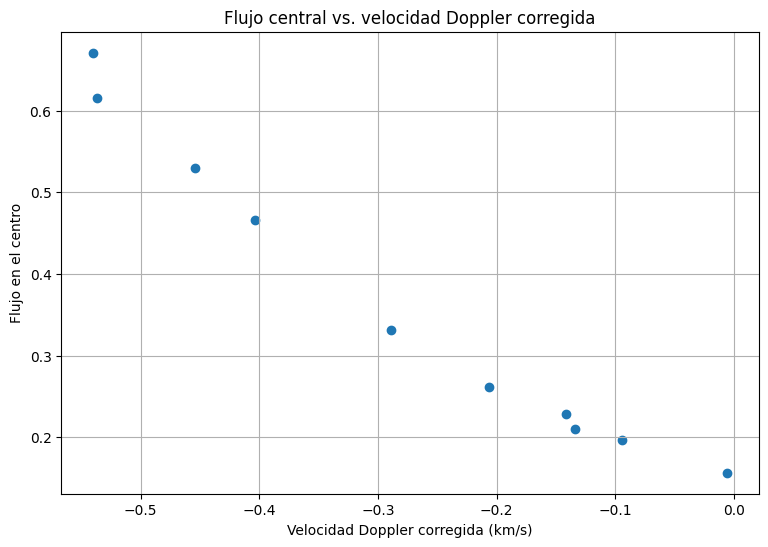

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
plt.figure(figsize=(9, 6))

plt.scatter(
    tabla['velocidad_corregida'],
    tabla['flujo_centro']
)

plt.xlabel('Velocidad Doppler corregida (km/s)')
plt.ylabel('Flujo en el centro')
plt.title('Flujo central vs. velocidad Doppler corregida')

plt.grid()
plt.savefig('flujo_central_vs_velocidad_Doppler_corregida.png', dpi=300, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('flujo_central_vs_velocidad_Doppler_corregida.png')